In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

In [4]:
data1 = pd.read_excel('../data/raw/wer_MC_data_org.xlsx', sheet_name='CSTB_processed')
data2 = pd.read_excel('../data/raw/wer_MC_data_org.xlsx', sheet_name='GBDB_data')
important_columns = ['bldg_use_type', 'bldg_use_subtype', 'bldg_project_status', 'site_country', 'bldg_area_gfa', 'bldg_floors_ag', 'bldg_floors_bg', 'bldg_struct_type', 'bldg_roof_type', 'inv_mat_1_type', 'GHG_sum_em_m2a']
data1 = data1[important_columns]
data2 = data2[important_columns]
data = pd.concat([data1, data2], ignore_index=True)
print(data.shape)
data = data.drop_duplicates()
print(data.shape)
data

(1781, 11)
(1701, 11)


,bldg_use_type,bldg_use_subtype,bldg_project_status,site_country,bldg_area_gfa,bldg_floors_ag,bldg_floors_bg,bldg_struct_type,bldg_roof_type,inv_mat_1_type,GHG_sum_em_m2a
0,Residential,Single family house,New Built,France,96.0,0.0,0.0,massive brick,Other,"Ceramics (e.g., fired clay bricks)",11.430481
1,Residential,Single family house,New Built,France,93.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.222277
2,Residential,Single family house,New Built,France,104.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.183415
3,Residential,Multi-family house,New Built,France,1106.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.303147
4,Residential,Multi-family house,New Built,France,1518.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.071612
...,...,...,...,...,...,...,...,...,...,...,...
1776,Residential,Single family house,New Built,USA,NaN,1.0,NaN,frame concrete,No data,No data,3.490000
1777,Residential,Single family house,New Built,USA,NaN,1.0,NaN,frame wood,No data,No data,2.680000
1778,Residential,Single family house,New Built,USA,NaN,1.0,NaN,frame steel,No data,No data,2.810000
1779,Residential,Single family house,New Built,USA,NaN,2.0,1.0,frame wood,Gable or saddle roof,"Earth (e.g., unfired clay, adobe, rammed earth...",6.680000


In [18]:
no_nulls = data[data.notnull().all(axis=1)]
print(no_nulls.shape)
no_nulls = no_nulls[~no_nulls.astype(str).apply(lambda col: col.str.contains("No data", regex=False)).any(axis=1)]
print(no_nulls.shape)
no_nulls

(612, 11)
(559, 11)


,bldg_use_type,bldg_use_subtype,bldg_project_status,site_country,bldg_area_gfa,bldg_floors_ag,bldg_floors_bg,bldg_struct_type,bldg_roof_type,inv_mat_1_type,GHG_sum_em_m2a
0,Residential,Single family house,New Built,France,96.0,0.0,0.0,massive brick,Other,"Ceramics (e.g., fired clay bricks)",11.430481
1,Residential,Single family house,New Built,France,93.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.222277
2,Residential,Single family house,New Built,France,104.0,0.0,0.0,massive brick,Gable or saddle roof,"Ceramics (e.g., fired clay bricks)",11.183415
3,Residential,Multi-family house,New Built,France,1106.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.303147
4,Residential,Multi-family house,New Built,France,1518.0,4.0,1.0,massive concrete,Flat roof,Concrete w/o reinforcement,13.071612
...,...,...,...,...,...,...,...,...,...,...,...
1612,Residential,Multi-family house,New Built,Italy,2968.0,7.0,1.0,massive brick,Single pitched roof,Concrete w/o reinforcement,10.500000
1627,Residential,Single family house,New Built,Italy,367.0,2.0,1.0,frame concrete,Other,Concrete w/o reinforcement,10.800000
1761,Non-residential,Office,New Built,USA,14715.0,8.0,3.0,frame wood,Flat roof,Concrete w/o reinforcement,6.670400
1772,Non-residential,Office,New Built,USA,14715.0,8.0,3.0,frame concrete,Flat roof,Concrete w/o reinforcement,9.007200


In [19]:
no_nulls_no_target = no_nulls.drop(columns=['site_country', 'GHG_sum_em_m2a'])

In [34]:
dummy = pd.get_dummies(no_nulls_no_target, prefix="var", prefix_sep="_", dtype=int)
X = dummy.to_numpy()
X

array([[9.6000e+01, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [9.3000e+01, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [1.0400e+02, 0.0000e+00, 0.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       ...,
       [1.4715e+04, 8.0000e+00, 3.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [1.4715e+04, 8.0000e+00, 3.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00],
       [1.4715e+04, 8.0000e+00, 3.0000e+00, ..., 0.0000e+00, 0.0000e+00,
        0.0000e+00]], shape=(559, 35))

In [25]:
X_quer = np.mean(X, axis=0)
n = X.shape[0]
X_std = np.std(X, axis=0, ddof=1)

R = ((X - X_quer) / X_std).T @ ((X - X_quer) / X_std) / (n - 1)
R

array([[ 1.        ,  0.55921279,  0.5417247 , ...,  0.00373044,
        -0.01319111, -0.09030057],
       [ 0.55921279,  1.        ,  0.52559044, ...,  0.05472618,
        -0.00239717, -0.08861465],
       [ 0.5417247 ,  0.52559044,  1.        , ..., -0.02906209,
        -0.02478181, -0.17956566],
       ...,
       [ 0.00373044,  0.05472618, -0.02906209, ...,  1.        ,
        -0.00856855, -0.06550687],
       [-0.01319111, -0.00239717, -0.02478181, ..., -0.00856855,
         1.        , -0.01370079],
       [-0.09030057, -0.08861465, -0.17956566, ..., -0.06550687,
        -0.01370079,  1.        ]], shape=(35, 35))

In [35]:
def corrmat(df,  R ):
    plt.figure(figsize=(10,10))
    plt.matshow( R, cmap="bwr", fignum=1, vmin=-1, vmax=1 )
    plt.colorbar( fraction=0.02 )
    plt.xticks( np.arange(0,35) )
    plt.gca().set_xticklabels( df.columns, rotation=90 )
    plt.yticks( np.arange(0,35) )
    plt.gca().set_yticklabels( df.columns )

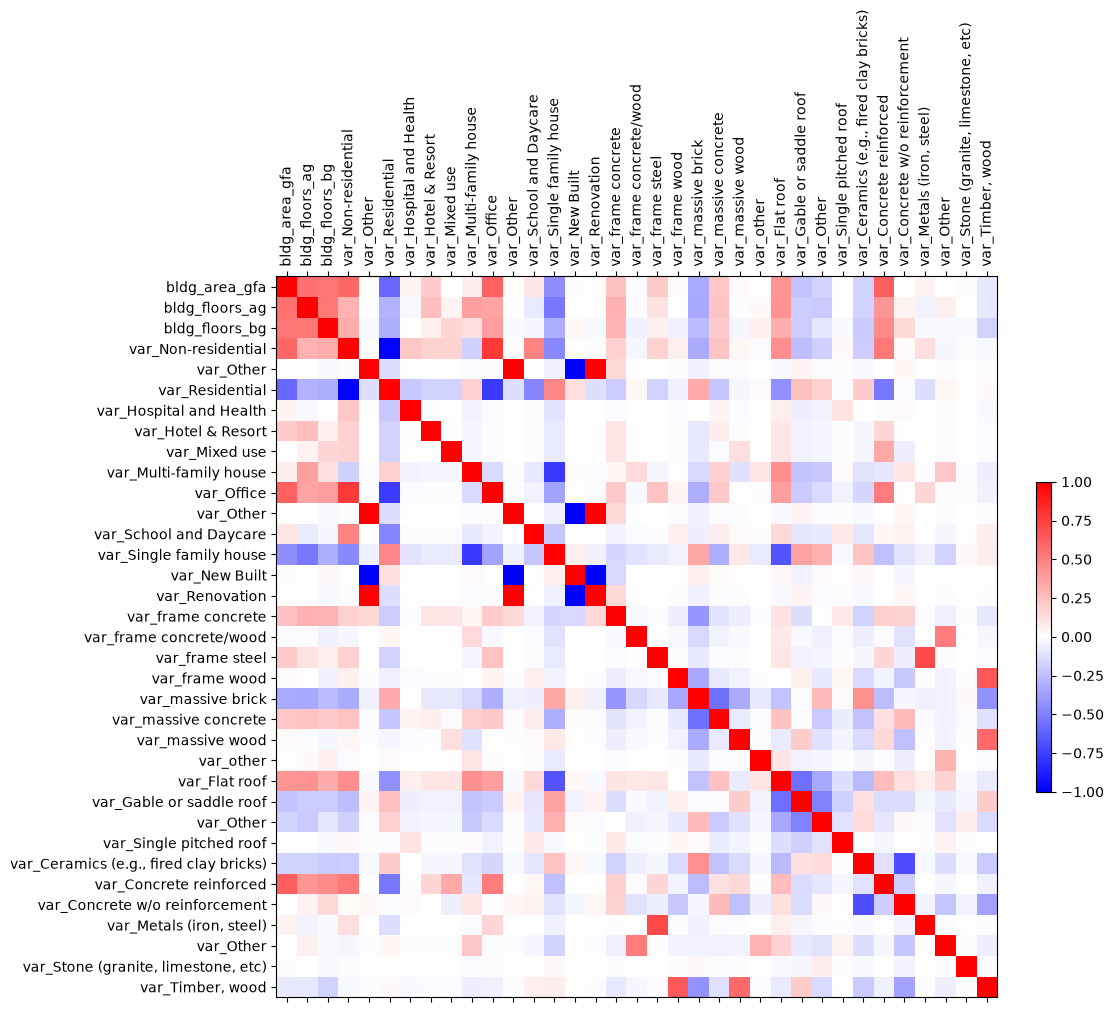

In [36]:
corrmat(dummy, R)

In [41]:
def sorted_eig(M):
    ## DEIN CODE
    ew_unsorted, ev_unsorted = np.linalg.eig(M)
    ew = np.array(sorted(list(ew_unsorted), key = lambda x: np.absolute(x), reverse=True))
    ev = []
    for wert in ew:
        idx = list(ew_unsorted).index(wert)
        ev.append(np.array(ev_unsorted[:, idx]))
    ev = np.array(ev)
    ev = ev.T
    return ew, ev

In [40]:
ew, ev = sorted_eig(R)

In [48]:
a = np.round(ew / np.sum(ew), 2)

a

array([ 0.17+0.j,  0.12+0.j,  0.08+0.j,  0.07+0.j,  0.05+0.j,  0.05+0.j,
        0.05+0.j,  0.04+0.j,  0.04+0.j,  0.03+0.j,  0.03+0.j,  0.03+0.j,
        0.03+0.j,  0.03+0.j,  0.03+0.j,  0.03+0.j,  0.02+0.j,  0.02+0.j,
        0.02+0.j,  0.01+0.j,  0.01+0.j,  0.01+0.j,  0.01+0.j,  0.01+0.j,
        0.01+0.j,  0.  +0.j,  0.  +0.j, -0.  +0.j, -0.  +0.j, -0.  +0.j,
       -0.  +0.j,  0.  +0.j, -0.  +0.j,  0.  +0.j,  0.  +0.j])

/home/anna/Projects/co2-probability/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/anna/Projects/co2-probability/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


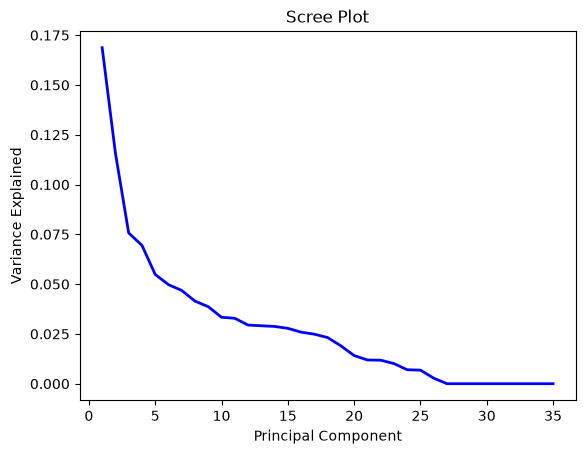

In [45]:
plt.plot(np.arange(1, len(a) + 1), ew / np.sum(ew), linewidth=2, color='blue')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.show()

In [55]:
list(a)

[np.complex128(0.17+0j),
 np.complex128(0.12+0j),
 np.complex128(0.08+0j),
 np.complex128(0.07+0j),
 np.complex128(0.05+0j),
 np.complex128(0.05+0j),
 np.complex128(0.05+0j),
 np.complex128(0.04+0j),
 np.complex128(0.04+0j),
 np.complex128(0.03+0j),
 np.complex128(0.03+0j),
 np.complex128(0.03+0j),
 np.complex128(0.03+0j),
 np.complex128(0.03+0j),
 np.complex128(0.03+0j),
 np.complex128(0.03+0j),
 np.complex128(0.02+0j),
 np.complex128(0.02+0j),
 np.complex128(0.02+0j),
 np.complex128(0.01+0j),
 np.complex128(0.01+0j),
 np.complex128(0.01+0j),
 np.complex128(0.01+0j),
 np.complex128(0.01+0j),
 np.complex128(0.01+0j),
 np.complex128(0j),
 np.complex128(0j),
 np.complex128(-0+0j),
 np.complex128(-0+0j),
 np.complex128(-0+0j),
 np.complex128(-0+0j),
 np.complex128(0j),
 np.complex128(-0+0j),
 np.complex128(0j),
 np.complex128(0j)]

/home/anna/Projects/co2-probability/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/anna/Projects/co2-probability/.venv/lib/python3.13/site-packages/matplotlib/cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


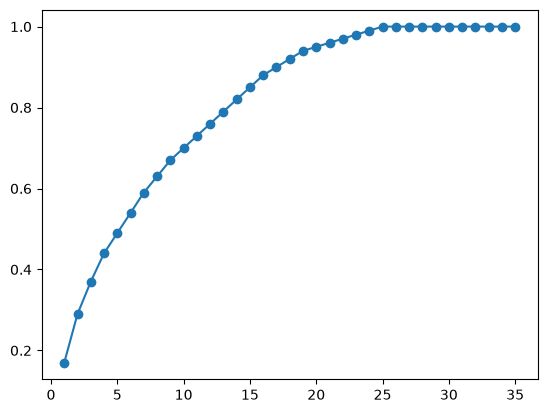

In [57]:
plt.plot(np.arange(1, 36), np.cumsum(list(a)), marker='o')

In [58]:
W = X @ R

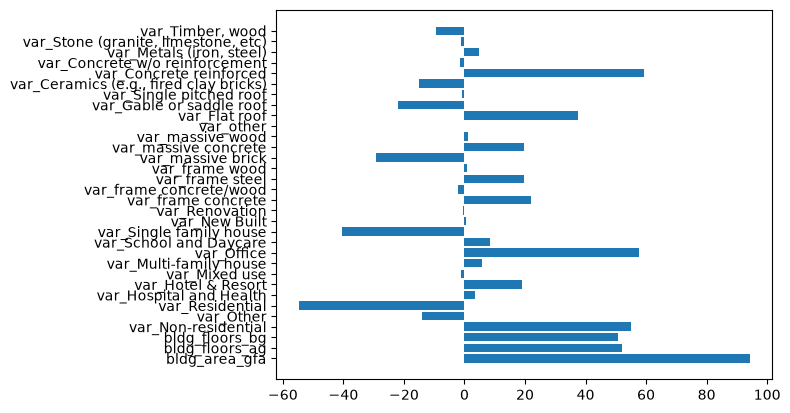

In [81]:
k = 0
pc = W[k, :]
plt.barh(y=dummy.columns, width=pc)
plt.yticks(rotation=0)
plt.show()

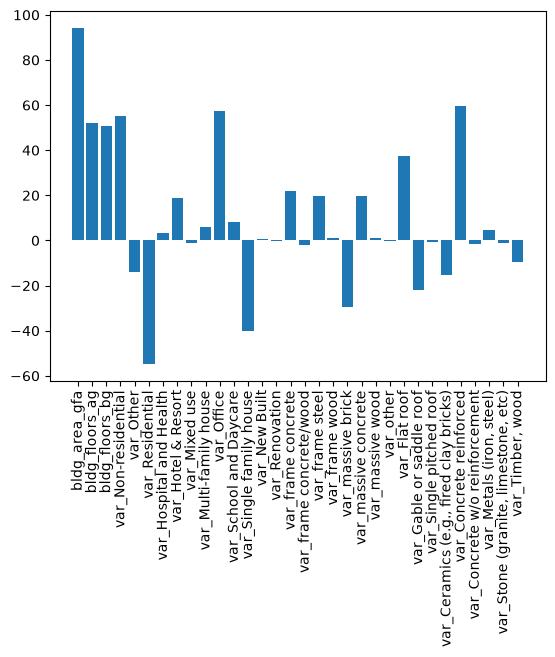

In [83]:
k = 0
pc = W[k, :]
plt.bar(x=dummy.columns, height=pc)
plt.xticks(rotation=90)
plt.show()